### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
print(np.__version__)

2.5.4


In [2]:

def psnr(reference, result):
    mse = np.mean((reference - result)**2)
    return 10 * np.log10(255**2 / mse)

In [3]:
def make_filter(kind, P, D0, n=None, highpass=False):
    u = np.arange(P) - P // 2
    U, V = np.meshgrid(u, u)
    D = np.sqrt(U**2 + V**2)

    if kind == "ideal":
        H = (D <= D0).astype(float)
    elif kind == "butterworth":
        H = 1 / (1 + (D / D0)**(2*n))
    elif kind == "gaussian":
        H = np.exp(-D**2 / (2*D0**2))
    else:
        raise ValueError("Unknown filter type")

    return 1 - H if highpass else H



### 2.1(a) Cutoff

At $D=D_0$:

$$
H_{\mathrm{ILPF}}=1,\qquad
H_{\mathrm{BLPF}}=\frac12,\qquad
H_{\mathrm{GLPF}}=e^{-1/2}\approx0.6065
$$

Thus, using the same numerical $D_0$ does not give equivalent attenuation. The ideal filter has a discontinuous cutoff, Butterworth reaches half-amplitude, and Gaussian retains approximately 60.65% amplitude.

**Matched Gaussian cutoff:**

To match the Butterworth half-amplitude radius,

$$
e^{-D_0^2/(2D_0'^2)}=\frac12
$$

Taking logarithms and rearranging,

$$
D_0'=\frac{D_0}{\sqrt{2\ln2}}\approx0.8493D_0
$$

This matched Gaussian cutoff is used in subsequent comparisons.

In [4]:

P, D0, n = 512, 40, 2
D0_g = D0 / np.sqrt(2 * np.log(2))

for kind, cutoff in [("ideal", D0), ("butterworth", D0),
                     ("gaussian", D0), ("gaussian", D0_g)]:
    H = make_filter(kind, P, cutoff, n)
    print(f"{kind:12s} D0={cutoff:6.2f}, H(40)={H[P//2, P//2+40]:.4f}")


ideal        D0= 40.00, H(40)=1.0000
butterworth  D0= 40.00, H(40)=0.5000
gaussian     D0= 40.00, H(40)=0.6065
gaussian     D0= 33.97, H(40)=0.5000


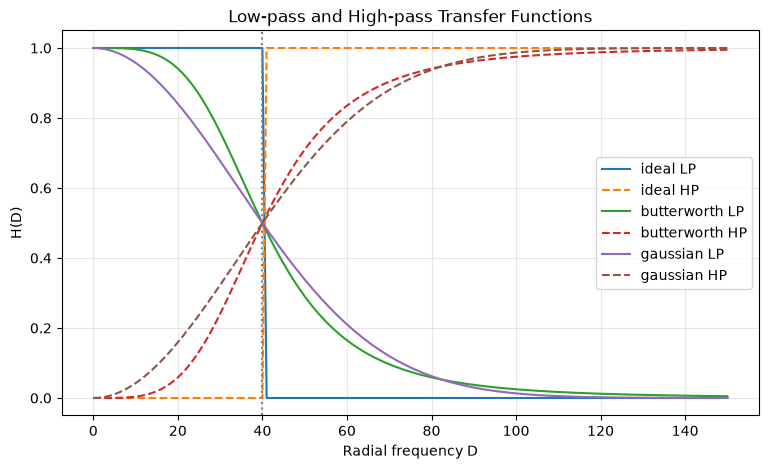

In [5]:
r = np.arange(0, 151)
plt.figure(figsize=(9, 5))

for kind in ["ideal", "butterworth", "gaussian"]:
    cutoff = D0_g if kind == "gaussian" else D0
    for hp in [False, True]:
        H = make_filter(kind, P, cutoff, n, highpass=hp)
        profile = H[P//2, P//2 + r]
        plt.plot(r, profile,
                 label=f"{kind} {'HP' if hp else 'LP'}",
                 linestyle="--" if hp else "-")

plt.axvline(D0, color="gray", linestyle=":")
plt.xlabel("Radial frequency D")
plt.ylabel("H(D)")
plt.title("Low-pass and High-pass Transfer Functions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:


img = np.asarray(Image.open("A2\\Q2_images\\Fig0441(a)(characters_test_pattern).tif").convert("L"), dtype=float)

N = img.shape[0]
P = 2 * N

F = np.fft.fftshift(np.fft.fft2(img, s=(P, P)))
power = np.abs(F)**2

u = np.arange(P) - P//2
U, V = np.meshgrid(u, u)
D = np.sqrt(U**2 + V**2)

In [7]:
radii = np.arange(int(D.max()) + 1)
alpha = np.array([100 * power[D <= r].sum() / power.sum() for r in radii])

print(f"{'Power (%)':<12} {'Radius (pixels)':<18}")
for target in [90, 95, 99, 99.5]:
    radius = radii[np.searchsorted(alpha, target)]
    print(f"{target:<12} {radius:<18}")


Power (%)    Radius (pixels)   
90           16                
95           46                
99           410               
99.5         559               



### 2.1(b) Energy-Based Cutoff Selection

The radial cumulative spectral power is calculated using the formula given

$$
\alpha(r)=100\frac{\sum_{D(u,v)\le r}|F(u,v)|^2}
{\sum_{u,v}|F(u,v)|^2}
$$

The smallest radii enclosing each target percentage are in the table above

**Observation:** A large fraction of spectral power is concentrated at low frequencies because the image contains large, slowly varying intensity regions. However, the remaining high frequencies represent sharp character boundaries and fine details, which can be visually important despite contributing relatively little total power.



### 2.1(c) Butterworth Inverse Design

Given

$$
H(10)=\frac{16}{17},\qquad H(40)=\frac1{17}
$$

Using

$$
H(D)=\frac1{1+(D/D_0)^{2n}}
$$

we obtain

$$
\left(\frac{10}{D_0}\right)^{2n}=\frac1{16},
\qquad
\left(\frac{40}{D_0}\right)^{2n}=16
$$

Dividing,

$$
4^{2n}=256=4^4
\implies n=2
$$

Substituting back,

$$
\left(\frac{10}{D_0}\right)^4=\frac1{16}
\implies D_0=20
$$

**Minimum order for at most 1% transmission at $D=2D_0$:**

$$
\frac1{1+2^{2n}}\le0.01
\implies 2^{2n}\ge99
$$

$$
n\ge\frac{\log_2 99}{2}\approx3.315
\implies n_{\min}=4
$$


In [8]:
# Verification
P = 512
H = make_filter("butterworth", P, 20, n=2)

print(f"H(10) = {H[P//2, P//2+10]:.6f} (expected {16/17:.6f})")
print(f"H(40) = {H[P//2, P//2+40]:.6f} (expected {1/17:.6f})")

for n in [3, 4]:
    H = make_filter("butterworth", P, 20, n=n)
    print(f"n={n}: H(2D0) = {H[P//2, P//2+40]:.6f}")


H(10) = 0.941176 (expected 0.941176)
H(40) = 0.058824 (expected 0.058824)
n=3: H(2D0) = 0.015385
n=4: H(2D0) = 0.003891



### 2.2 Pre-Implementation Prediction
![title](Q2-written-prediction.jpeg)

In [9]:
N, P = 512, 1024
A, B = 50, 200

step = np.full((N, N), A, dtype=float)
step[128:384, 128:384] = B


def apply_filter(img, kind, D0, n=None):
    M, N = img.shape
    P = 2 * max(M, N)
    F = np.fft.fftshift(np.fft.fft2(img, s=(P, P)))
    H = make_filter(kind, P, D0, n)
    return np.fft.ifft2(np.fft.ifftshift(F * H)).real[:M, :N]

In [10]:
def edge_measure(im, D0):
    profile = im[256]
    edge = 128
    width = min(100, int(2*P/D0) + 5)
    segment = profile[edge:edge+width]

    peaks = np.where(
        (segment[1:-1] > segment[:-2]) &
        (segment[1:-1] > segment[2:])
    )[0] + 1

    peak = peaks[0] if len(peaks) else np.argmax(segment)
    overshoot = 100 * (segment.max() - B) / (B-A)

    return overshoot, peak


In [11]:
print(f"{'D0':<6} {'Pred. OS%':>12} {'Measured OS%':>15} {'Pred. dist':>12} {'Meas. dist':>12}")
for D0 in [10, 40, 80]:
    out = apply_filter(step, "ideal", D0)
    os, dist = edge_measure(out, D0)
    print(f"{D0:<6} {8.949:.2f}%{'':>6} {os:>13.2f}% {P/(2*D0):>12.2f} {dist:>12}")

D0        Pred. OS%    Measured OS%   Pred. dist   Meas. dist
10     8.95%                3.44%        51.20           50
40     8.95%                8.27%        12.80           12
80     8.95%                8.78%         6.40            6


### Observation

The theoretical Gibbs overshoot is approximately 8.949%, while the predicted first-peak distance is \(P/(2D_0)\).

The measured peak distances closely follow this prediction, with small deviations caused by sampling at integer pixel positions.

The measured overshoot approaches the theoretical value as \(D_0\) increases. At \(D_0=10\), the overshoot is smaller because the image contains a finite-width square rather than an isolated infinite step.

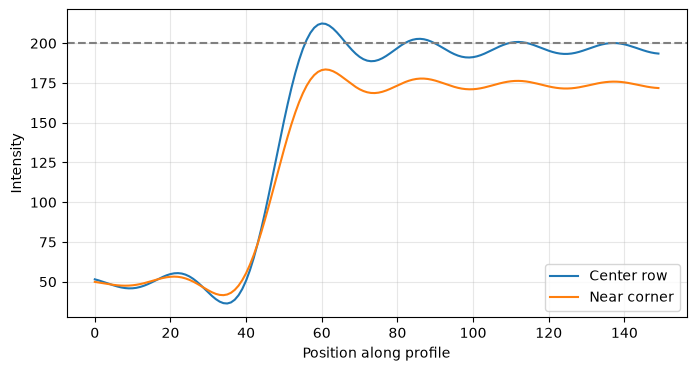

In [12]:
out = apply_filter(step, "ideal", 40)

plt.figure(figsize=(8, 4))
plt.plot(out[256, 80:230], label="Center row")
plt.plot(out[132, 80:230], label="Near corner")
plt.axhline(B, color="gray", linestyle="--")
plt.xlabel("Position along profile")
plt.ylabel("Intensity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [13]:
orders = [1, 2, 3, 5, 10, 20]
print(f"{'Order':<8} {'Overshoot (%)':>15} {'Negative mass ratio':>22}")
for n in orders:
    out = apply_filter(step, "butterworth", 40, n)
    os, _ = edge_measure(out, 40)
    H = make_filter("butterworth", P, 40, n)
    h = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(H[P//2]))).real
    neg_ratio = np.maximum(-h, 0).sum() / np.abs(h).sum()
    print(f"{n:<8} {os:>15.3f} {neg_ratio:>22.6f}")


Order      Overshoot (%)    Negative mass ratio
1                 -0.000               0.000022
2                  3.359               0.061567
3                  5.603               0.107653
5                  7.499               0.159227
10                 8.486               0.213035
20                 8.434               0.252655


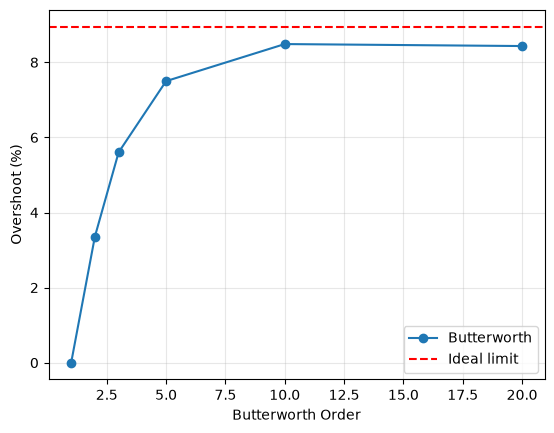

In [14]:
overshoots = [edge_measure(apply_filter(step, "butterworth", 40, n), 40)[0] for n in orders]
plt.plot(orders, overshoots, "o-", label="Butterworth")
plt.axhline(8.949, color="red", linestyle="--", label="Ideal limit")
plt.xlabel("Butterworth Order")
plt.ylabel("Overshoot (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 2.2(b) Butterworth Order Sweep

For $D_0=40$, orders $n=\{1,2,3,5,10,20\}$ are tested.

The 1-D spatial kernel is obtained from

$$
h(x)=\mathcal F^{-1}\{H(u,0)\}
$$

The negative kernel mass ratio is

$$
R_-=\frac{\sum_x\max(-h(x),0)}{\sum_x|h(x)|}
$$

**Why order 1 has no ringing:**

For $n=1$,

$$
H(f)=\frac{1}{1+(f/f_c)^2}
\implies h(x)=\pi f_c e^{-2\pi f_c|x|}\ge0
$$

Higher orders produce negative kernel lobes, permitting overshoot.

**Non-negative kernel proof:**

For a normalized kernel $h(t)\ge0$ and step height $B-A$,

$$
g(x)=A+(B-A)\int_{-\infty}^{x}h(t)\,dt
$$

Since the integral lies in $[0,1]$,

$$
\boxed{A\le g(x)\le B}
$$

Thus, a normalized non-negative spatial kernel cannot produce overshoot on a step.

As Butterworth order increases, its cutoff becomes sharper, and its measured ringing approaches the ideal-filter limit.


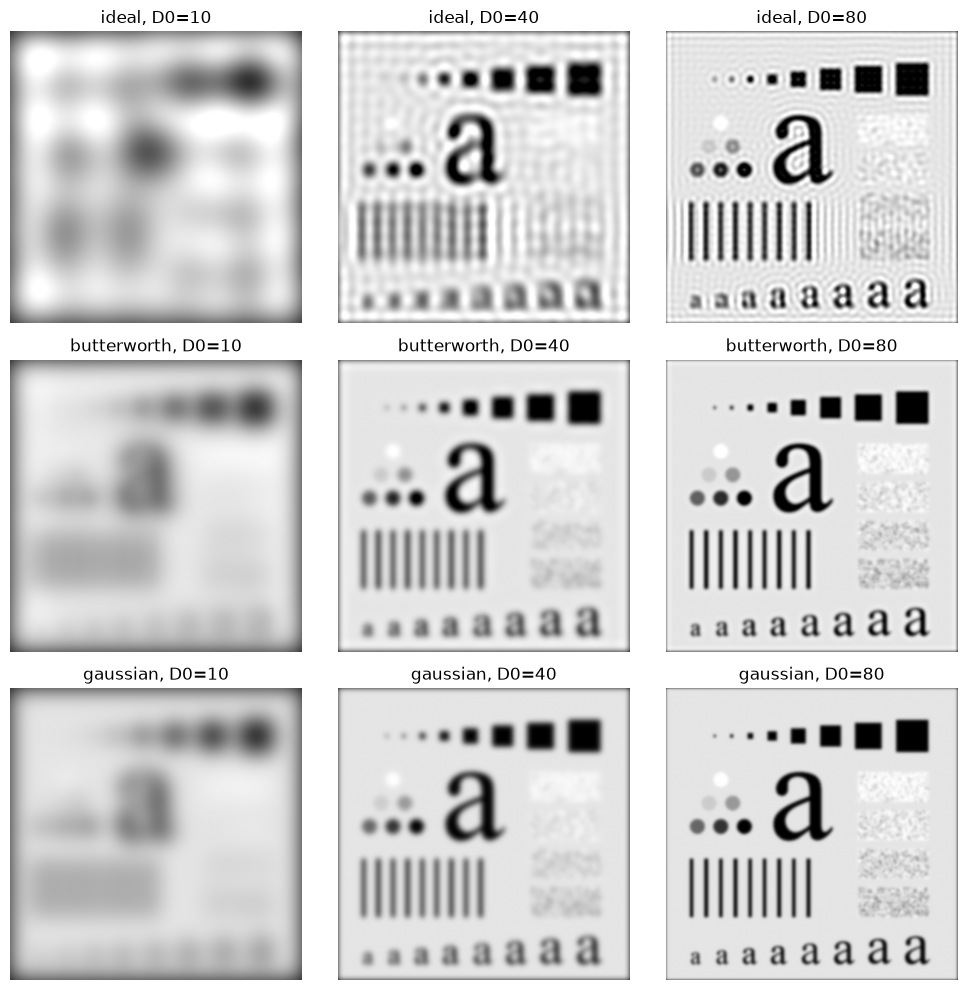

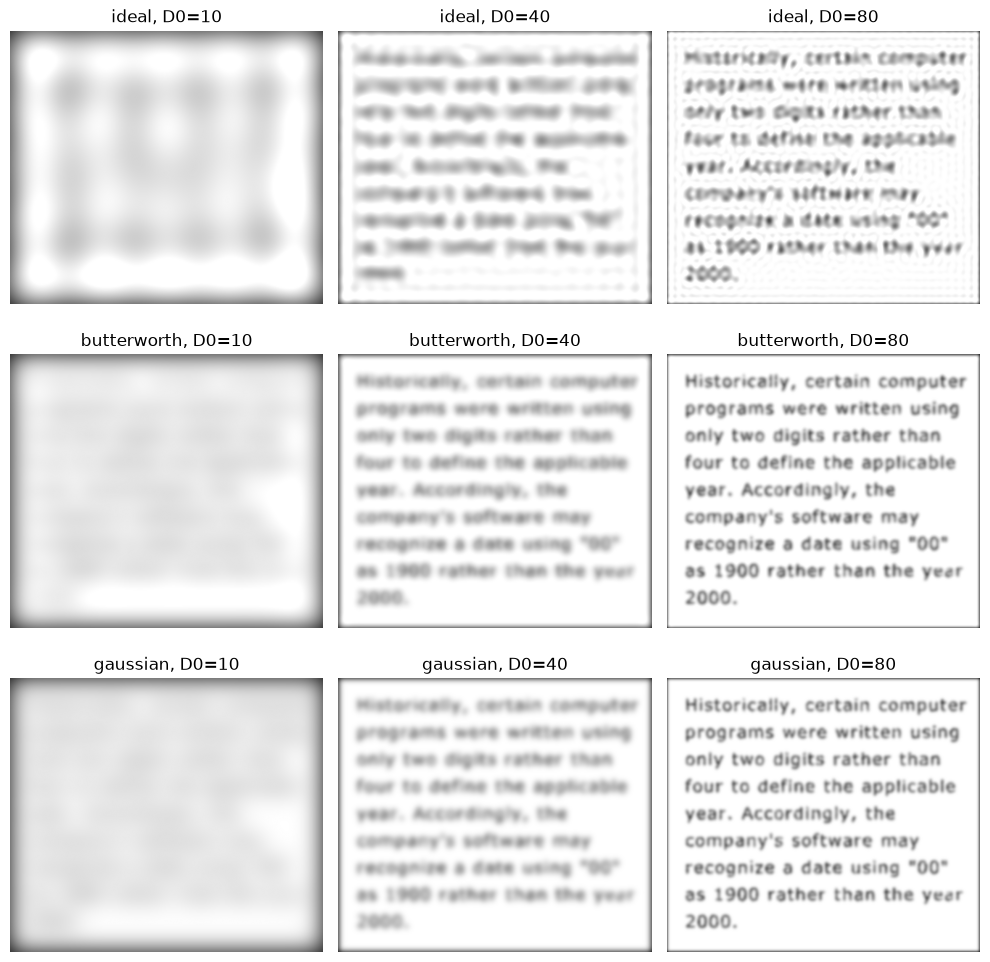

In [15]:
def comparison_grid(filename):
    img = np.asarray(Image.open(filename).convert("L"), dtype=float)
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))

    for i, kind in enumerate(["ideal", "butterworth", "gaussian"]):
        for j, D0 in enumerate([10, 40, 80]):
            cutoff = D0 / np.sqrt(2*np.log(2)) if kind == "gaussian" else D0
            out = apply_filter(img, kind, cutoff, n=2)
            axes[i, j].imshow(out, cmap="gray", vmin=0, vmax=255)
            axes[i, j].set_title(f"{kind}, D0={D0}")
            axes[i, j].axis("off")
    plt.tight_layout()
    plt.show()

comparison_grid("A2\\Q2_images\\Fig0441(a)(characters_test_pattern).tif")
comparison_grid("A2\\Q2_images\\Fig0419(a)(text_gaps_of_1_and_2_pixels).tif")


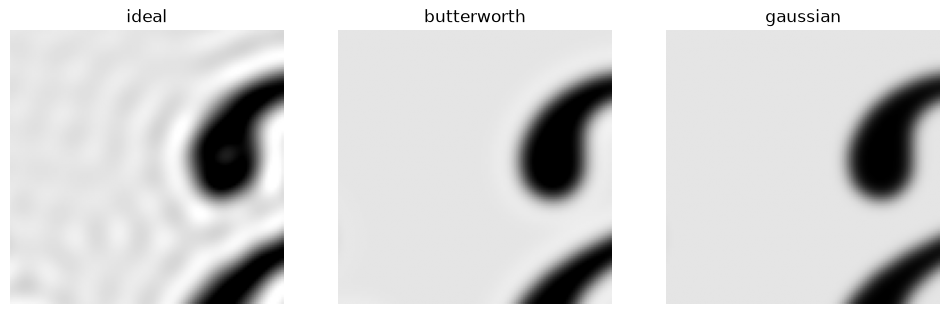

In [16]:
# evidence ringing 1
img = np.asarray(Image.open("A2\\Q2_images\\Fig0441(a)(characters_test_pattern).tif").convert("L"), dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, kind in zip(axes, ["ideal", "butterworth", "gaussian"]):
    cutoff = 80 / np.sqrt(2*np.log(2)) if kind == "gaussian" else 80
    out = apply_filter(img, kind, cutoff, n=2)
    ax.imshow(out[180:300, 180:300], cmap="gray", vmin=0, vmax=255)
    ax.set_title(kind)
    ax.axis("off")

plt.show()


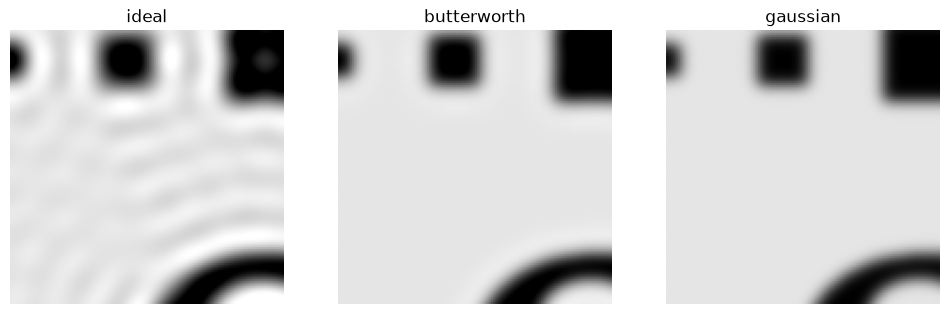

In [17]:
# evidence ringing 2
img = np.asarray(Image.open("A2\\Q2_images\\Fig0441(a)(characters_test_pattern).tif").convert("L"), dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, kind in zip(axes, ["ideal", "butterworth", "gaussian"]):
    cutoff = 80 / np.sqrt(2*np.log(2)) if kind == "gaussian" else 80
    out = apply_filter(img, kind, cutoff, n=2)
    ax.imshow(out[100:220, 200:320], cmap="gray", vmin=0, vmax=255)
    ax.set_title(kind)
    ax.axis("off")

plt.show()



### 2.2(c) Visual Comparison

The three filter families were compared at $D_0=\{10,40,80\}$, using Butterworth order $n=2$ and the matched Gaussian half-amplitude radius.

**Sharpness–ringing trade-off:**
- **Ideal:** Sharp frequency cutoff produces the strongest ringing near character boundaries.
- **Butterworth:** Smoother cutoff reduces ringing while retaining more edge sharpness than aggressive Gaussian smoothing.
- **Gaussian:** Smooth frequency response avoids pronounced ringing but produces smoother, more blurred edges.
- Increasing $D_0$ generally preserves finer image details and narrows the spatial extent of ringing.

The zoomed edge comparisons illustrate the oscillatory bright/dark bands produced by the ideal filter near sharp boundaries.



### 2.2(d) Gaussian Equivalence

The Fourier transform of a spatial Gaussian with standard deviation $\sigma_s$ is

$$
H(f_x,f_y)=e^{-2\pi^2\sigma_s^2(f_x^2+f_y^2)}
$$

Using $f_x=u/P$, $f_y=v/P$ and $D^2=u^2+v^2$,

$$
H(u,v)=e^{-2\pi^2\sigma_s^2D^2/P^2}
$$

Comparing with the given Gaussian transfer function,

$$
H_{\mathrm{GLPF}}(D)=e^{-D^2/(2D_0^2)}
$$

we obtain

$$
\sigma_s=\frac{P}{2\pi D_0}
$$


In [18]:

from scipy.ndimage import gaussian_filter

print(f"{'D0':<8} {'Spatial sigma':>15} {'Max abs error':>18}")

for D0 in [10, 40, 160]:
    sigma_s = P / (2*np.pi*D0)

    freq = apply_filter(step, "gaussian", D0)
    spatial = gaussian_filter(step, sigma=sigma_s,
                              mode="constant", cval=0)

    error = np.max(np.abs(freq - spatial))
    print(f"{D0:<8} {sigma_s:>15.4f} {error:>18.6f}")


D0         Spatial sigma      Max abs error
10               16.2975           0.008742
40                4.0744           0.007366
160               1.0186           0.065651



### Gaussian Equivalence Results
The frequency-domain and spatial Gaussian implementations approximate the same continuous convolution operation, but their outputs are not exactly identical.
Differences arise from discrete sampling, finite kernel truncation, and numerical implementation. At larger $D_0$, the equivalent spatial Gaussian becomes narrower, making sampling effects more significant.

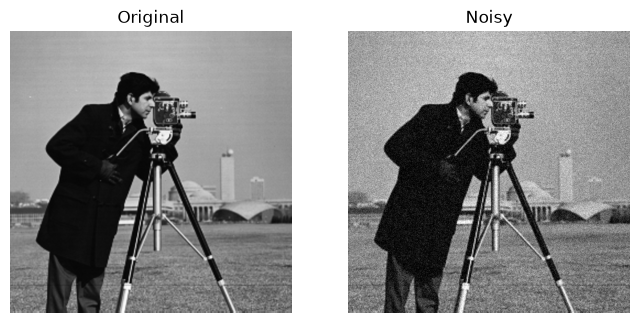

In [19]:
clean = np.asarray(Image.open("A2\\Q2_images\\cameraman.tif").convert("L"), dtype=float)

rng = np.random.default_rng(42)
noisy = clean + rng.normal(0, 20, clean.shape)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, im, title in zip(ax, [clean, noisy], ["Original", "Noisy"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255)
    a.set_title(title)
    a.axis("off")
plt.show()


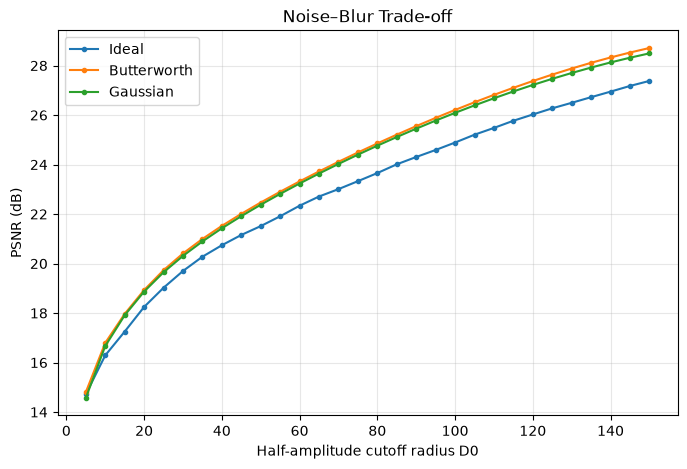

In [20]:
D0_values = np.arange(5, 151, 5)
scores = {}
for kind in ["ideal", "butterworth", "gaussian"]:
    scores[kind] = []
    for D0 in D0_values:
        cutoff = D0 / np.sqrt(2*np.log(2)) if kind == "gaussian" else D0
        out = apply_filter(noisy, kind, cutoff, n=2)
        scores[kind].append(psnr(clean, out))

plt.figure(figsize=(8, 5))
for kind in scores:
    plt.plot(D0_values, scores[kind], marker=".", label=kind.capitalize())
plt.xlabel("Half-amplitude cutoff radius D0")
plt.ylabel("PSNR (dB)")
plt.title("Noise–Blur Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [21]:
print(f"{'Filter':<15} {'Optimal D0':>12} {'Peak PSNR (dB)':>17}")
for kind, values in scores.items():
    i = np.argmax(values)
    print(f"{kind:<15} {D0_values[i]:>12} {values[i]:>17.3f}")


Filter            Optimal D0    Peak PSNR (dB)
ideal                    150            27.380
butterworth              150            28.710
gaussian                 150            28.494


### Noise–Blur Trade-off

At small cutoff radii, strong low-pass filtering removes noise but also suppresses important image details, resulting in substantial blur and lower PSNR.

As the cutoff increases, more image detail is preserved, improving PSNR. Beyond a suitable cutoff, further increases would eventually retain excessive noise.

The ideal filter achieves a lower peak PSNR because its abrupt frequency cutoff produces oscillatory spatial-domain ringing near sharp image boundaries. Butterworth and Gaussian filters have smoother transfer functions, reducing such artifacts and giving a more gradual noise-versus-detail trade-off.

Note the Optimal D0 is within the tested range and not global (for global very large set of values need to be tested)

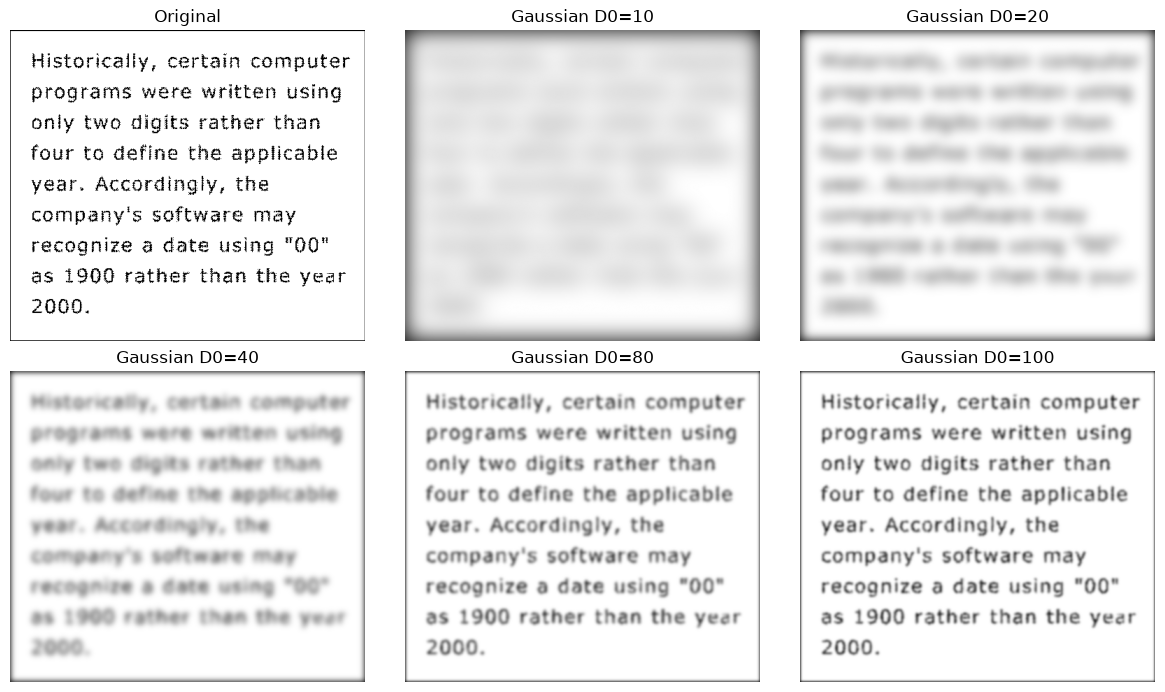

In [22]:

text_img = np.asarray(Image.open("A2\\Q2_images\\Fig0419(a)(text_gaps_of_1_and_2_pixels).tif").convert("L"), dtype=float)

cutoffs = [10, 20, 40, 80, 100]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

axes[0].imshow(text_img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")

for i, D0 in enumerate(cutoffs, 1):
    out = apply_filter(text_img, "gaussian", D0)
    axes[i].imshow(out, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"Gaussian D0={D0}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


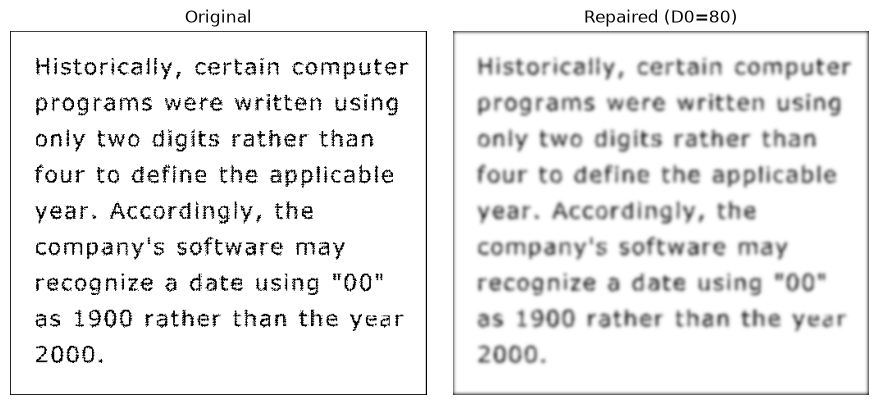

In [23]:

D0_repair = 80
repaired = apply_filter(text_img, "gaussian", D0_repair)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, im, title in zip(axes, [text_img, repaired],
                         ["Original", f"Repaired (D0={D0_repair})"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


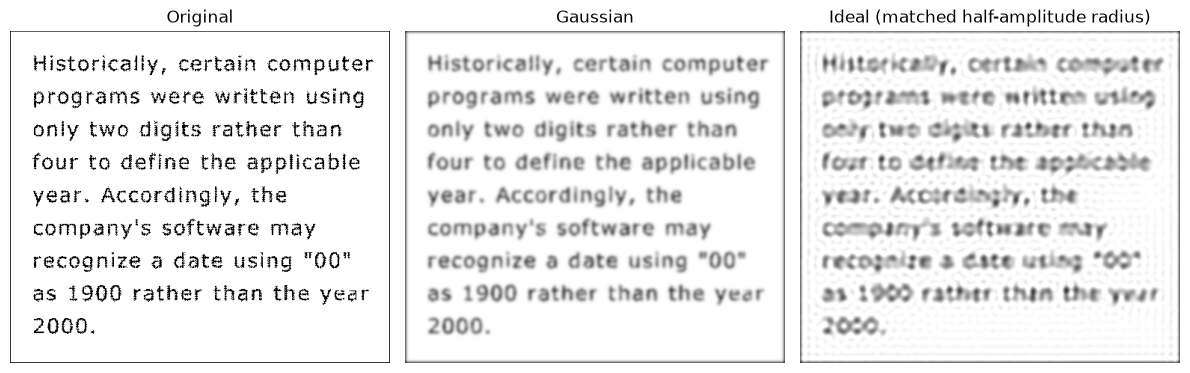

In [24]:
half_radius = D0_repair * np.sqrt(2*np.log(2))

ideal_repair = apply_filter(
    text_img, "ideal", half_radius
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, im, title in zip(
    axes,
    [text_img, repaired, ideal_repair],
    ["Original", "Gaussian", "Ideal (matched half-amplitude radius)"]
):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()



### 2.3(b) Character Repair
**Selected cutoff:** $D_0=80$
Gaussian smoothing spreads intensity across neighboring pixels, helping bridge narrow gaps in character strokes.
At smaller $D_0$, stronger smoothing may merge nearby strokes and reduce legibility. At larger $D_0$, less smoothing occurs, leaving more gaps unconnected.

if we replace the Gaussian with an ideal filter at the same half-amplitude radius, the ideal filter's oscillatory impulse response introduces ringing, false dark and bright bands, and less controlled joining of character strokes. The Gaussian is repair visually appears to perform better for smooth and predictable repair


### 2.3(c) High-Pass Filtering and DC Term

For all three high-pass filters,

$$
H_{\mathrm{HP}}(0,0)=1-H_{\mathrm{LP}}(0,0)=0
$$

Therefore, the DC component is removed, giving zero mean over the full padded inverse-DFT image.
For high-frequency emphasis, choose $k_1=k_2=1$:

$$
H_{\mathrm{HFE}}(u,v)=1+H_{\mathrm{HP}}(u,v)
$$
At the origin,
$$
H_{\mathrm{HFE}}(0,0)=1
$$
Hence, high-frequency emphasis restores the original DC component while enhancing high-frequency details.

In [25]:

thumb = np.asarray(Image.open("A2\\Q2_images\\Fig0457(a)(thumb_print).tif").convert("L"), dtype=float)

D0 = 40
hp_outputs = {}

for kind in ["ideal", "butterworth", "gaussian"]:
    cutoff = D0 / np.sqrt(2*np.log(2)) if kind == "gaussian" else D0
    hp_outputs[kind] = thumb - apply_filter(thumb, kind, cutoff, n=4)

print(f"{'Filter':<15} {'Mean HP output':>18}")
for kind, out in hp_outputs.items():
    print(f"{kind:<15} {out.mean():>18.4f}")


Filter              Mean HP output
ideal                       1.7636
butterworth                 1.8144
gaussian                    2.5722


After cropping to the original image dimensions, the remaining region is not required to have zero mean. Boundary-related positive and negative contributions can lie outside the cropped portion.

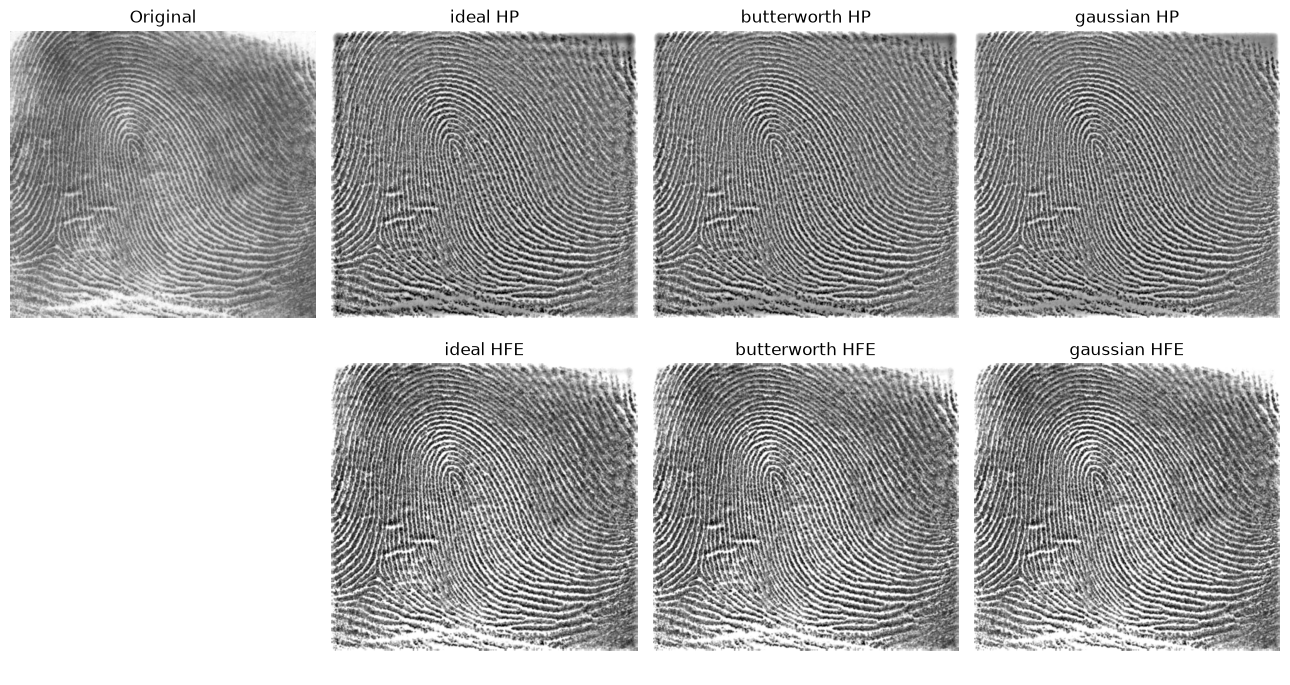

In [26]:

fig, axes = plt.subplots(2, 4, figsize=(13, 7))

axes[0, 0].imshow(thumb, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")

axes[1, 0].axis("off")

for i, (kind, hp) in enumerate(hp_outputs.items(), 1):
    axes[0, i].imshow(hp, cmap="gray", vmin=-80, vmax=80)
    axes[0, i].set_title(f"{kind} HP")

    enhanced = thumb + hp
    axes[1, i].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
    axes[1, i].set_title(f"{kind} HFE")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


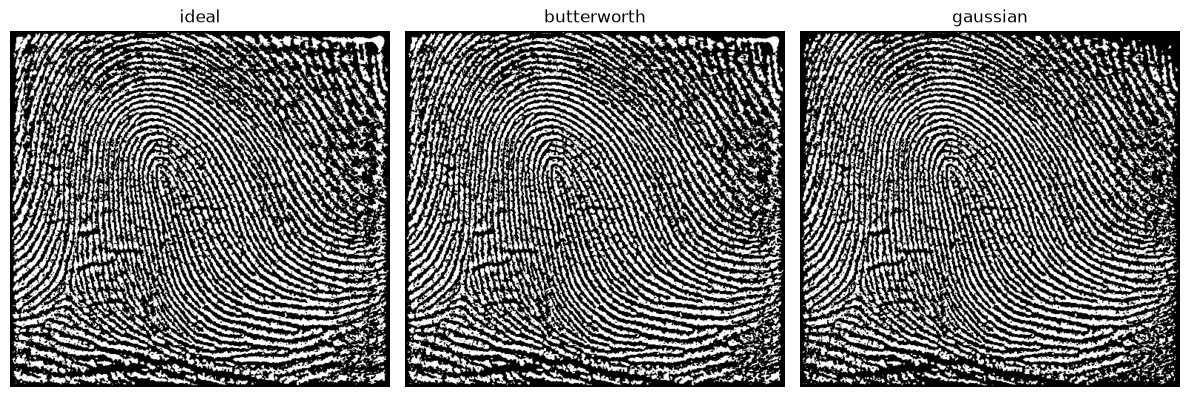

In [27]:

threshold = -10

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (kind, hp) in zip(axes, hp_outputs.items()):
    binary = hp < threshold
    ax.imshow(binary, cmap="gray")
    ax.set_title(kind)
    ax.axis("off")

plt.tight_layout()
plt.show()


Butterworth produces the marginally cleanest ridge map in this experiment, although the three results are visually very similar. Its smoother frequency cutoff reduces ringing compared with the ideal filter while retaining slightly better ridge separation than the Gaussian filter.


### High-Pass Filtering and Ridge Extraction
High-pass filtering removes slowly varying intensity components while retaining rapid changes associated with fingerprint ridges.
High-frequency emphasis with $k_1=k_2=1$ preserves the original DC component while strengthening ridge details.

**Ridge extraction:** The signed high-pass outputs were thresholded at $-10$ to extract dark ridge responses.
The three binary maps are compared for ridge continuity, noise and false responses. The filter producing the most continuous ridges with the fewest spurious structures is preferred.
